### Import library

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

path = "./data/raw"

df = pd.read_csv(path + "/train.csv")
df_test = pd.read_csv(path + "/test.csv")

### View data on table

In [12]:
# Display the first 5 examples

df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


### Quickly do a basic exploration of the dataset

In [6]:
df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


In [8]:
df.shape

(8693, 14)

### Initial Inspection and Standardization

**Decision guide based on how much is missing**

| % Missing	 | Recommended Action                              |
|-----------|-------------------------------------------------|
| < 5%      | Drop the rows                                   |
| 5% – 40%  | Fill with median (numbers) or mode (categories) |
| > 40%     | Consider dropping the column                    |

In [16]:
# Step 1: Standardize column names: remove extra spaces, make lower cases,
# replace spaces within the column names with _
df.columns = (df.columns.str.strip().str.lower().str.replace(' ', '_', regex=False))

# Step 2: Handles duplicates value: Check for drop the rows
df.duplicated().sum()

# Remove them
df = df.drop_duplicates()

# Step 3: Handle missing values by following the Decision Guide
print(f"Missing Values per column: \n{df.isnull().sum()}\n")

# Calculate the percentage of missing cell for each rows
df.isnull().mean(axis=1) * 100

Missing Values per column: 
passengerid       0
homeplanet      201
cryosleep       217
cabin           199
destination     182
age             179
vip             203
roomservice     181
foodcourt       183
shoppingmall    208
spa             183
vrdeck          188
name            200
transported       0
dtype: int64



0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
8688    0.0
8689    0.0
8690    0.0
8691    0.0
8692    0.0
Length: 8693, dtype: float64

In [17]:
# Fill missing value
df['age'] = df['age'].fillna(df['age'].median())

money_cols = ['roomservice', 'foodcourt', 'shoppingmall', 'spa', 'vrdeck']
df[money_cols] = df[money_cols].fillna(0)


category_cols = ['homeplanet', 'cryosleep', 'destination', 'vip']
for col in category_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

df['cabin'] = df["cabin"].fillna('Unknown')
df['name'] = df['name'].fillna('Unknown')

# Print result again
print(f'Missing Values per column:\n{df.isnull().sum()}\n')
df.isnull().mean(axis=1) * 100

Missing Values per column:
passengerid     0
homeplanet      0
cryosleep       0
cabin           0
destination     0
age             0
vip             0
roomservice     0
foodcourt       0
shoppingmall    0
spa             0
vrdeck          0
name            0
transported     0
dtype: int64



0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
8688    0.0
8689    0.0
8690    0.0
8691    0.0
8692    0.0
Length: 8693, dtype: float64

### Fixing Data Types

In [27]:
df.dtypes

passengerid         str
homeplanet          str
cryosleep          bool
cabin               str
destination         str
age             float64
vip                bool
roomservice     float64
foodcourt       float64
shoppingmall    float64
spa             float64
vrdeck          float64
name                str
transported        bool
dtype: object

In [29]:
obj_columns = ['cryosleep', 'vip']

for col in obj_columns:
    df[col] = df[col].astype('bool')

df.dtypes

passengerid         str
homeplanet          str
cryosleep          bool
cabin               str
destination         str
age             float64
vip                bool
roomservice     float64
foodcourt       float64
shoppingmall    float64
spa             float64
vrdeck          float64
name                str
transported        bool
dtype: object

In [37]:
df.to_csv("./data/clean/1train_cleaned.csv", index=False)

### Univariate, Bivariate, Multivariate Analysis

a). Univariate

- Univariate analysis means analyzing one variable/column/feature at a time.
- It helps us understand:
    1. Distribution
    2. Frequency
    3. Spread
    4. Outliers

i) Numerical Columns

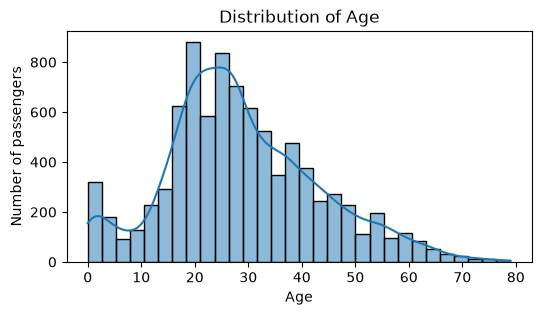

In [13]:
# What is the distribution of age?
plt.figure(figsize=(6, 3))

sns.histplot(data=df, x="age",
             bins=30, kde=True)

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Number of passengers")
plt.show()

The AGE distribution is concentrate around 20-40 years old, with fewer passengers at the extremes. The distribution appears slightly right-skewed.

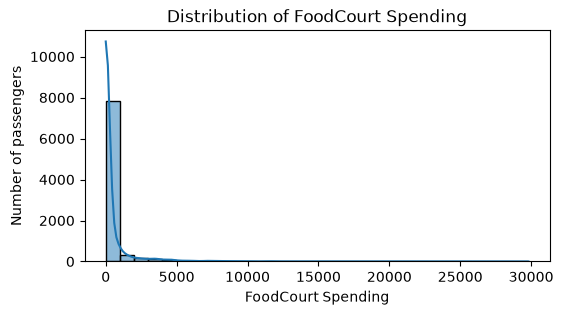

In [14]:
# What is the distribution of FoodCourt spending?
plt.figure(figsize=(6, 3))

sns.histplot(data=df, x="foodcourt",
             bins=30, kde=True)

plt.title("Distribution of FoodCourt Spending")
plt.xlabel("FoodCourt Spending")
plt.ylabel("Number of passengers")
plt.show()

FoodCourt Spending is concentrate at low Spending with most passengers. The distribution is also slightly right-skewed.

ii) Categorical data

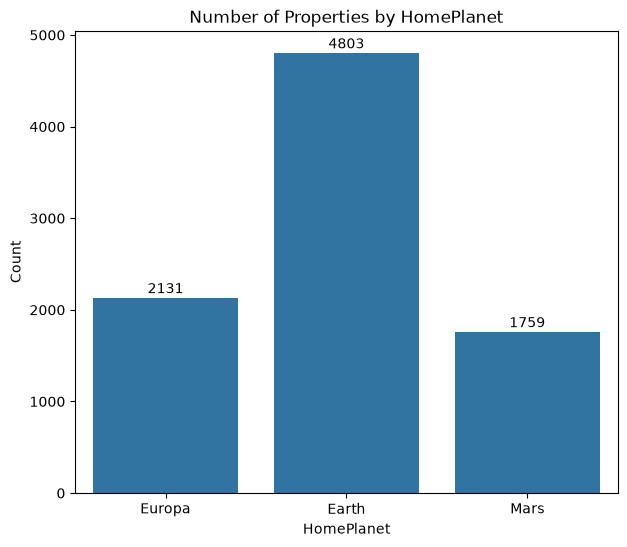

In [15]:
# Counts of HomePlanet
plt.figure(figsize=(7, 6))

ax = sns.countplot(data=df, x='homeplanet')

plt.title('Number of Properties by HomePlanet')
plt.xlabel('HomePlanet')
plt.ylabel('Count')

for rect in ax.patches:
    y_value = rect.get_height()
    x_value = rect.get_x() + rect.get_width() / 2
    space = 1
    label = "{:.0f}".format(y_value)
    plt.annotate(label, (x_value, y_value), xytext=(0, space), textcoords="offset points", ha='center', va='bottom')

plt.show()

The Earth is most passengers all of them, follow by Mars and Europa has the fewest passengers

b). Bivariate Analysis

- Bivariate analysis means analyzing the relationship between two variables.
- It helps us understand:
    1. Relationships.
    2. Comparisons.
    3. Association.
    4. Correlation.
    5. Difference between groups.

i) Numerical vs Numerical

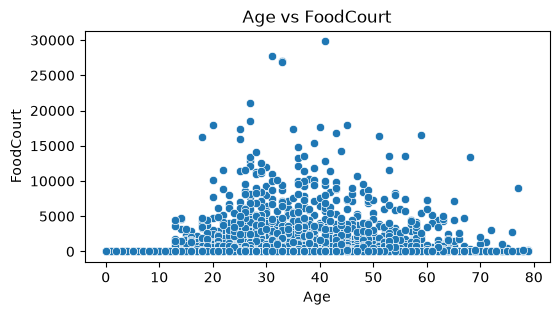

In [16]:
# Age vs FoodCourt
plt.figure(figsize=(6, 3))

sns.scatterplot(df, x="age", y="foodcourt")

plt.title("Age vs FoodCourt")
plt.xlabel("Age")
plt.ylabel("FoodCourt")
plt.show()

Most passengers have low FoodCourt spending regardless of age. There is no clear correlation between age and FoodCourt spending.

ii) Numerical vs Categorical

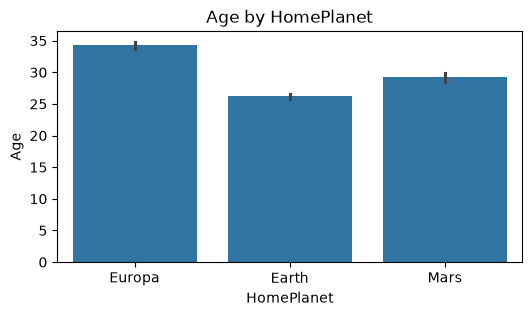

In [17]:
# Age vs HomePlanet
plt.figure(figsize=(6, 3))

sns.barplot(df, x='homeplanet', y='age', estimator='mean')
plt.title('Age by HomePlanet')
plt.xlabel('HomePlanet')
plt.ylabel("Age")
plt.show()

The oldest passengers are mostly from Europa, Mars, and Earth.

iii) Categorical vs Categorical

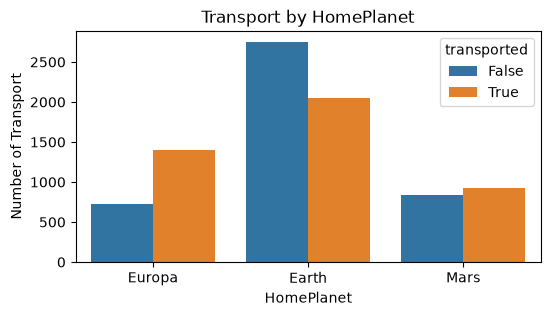

In [18]:
# Transport vs HomePlanet
plt.figure(figsize=(6, 3))

sns.countplot(data=df, x='homeplanet', hue='transported')

plt.title('Transport by HomePlanet')
plt.xlabel('HomePlanet')
plt.ylabel('Number of Transport')
plt.show()

Europa has more transported passengers than non-transported passengers. In contrast, Earth has more non-transported passengers, while Mars has a similar number of transported and non-transported passengers.

c). Multivariate
- Multivariate analysis means analyzing three or more variables at the same time.
- it helps us understand more complex relationships.

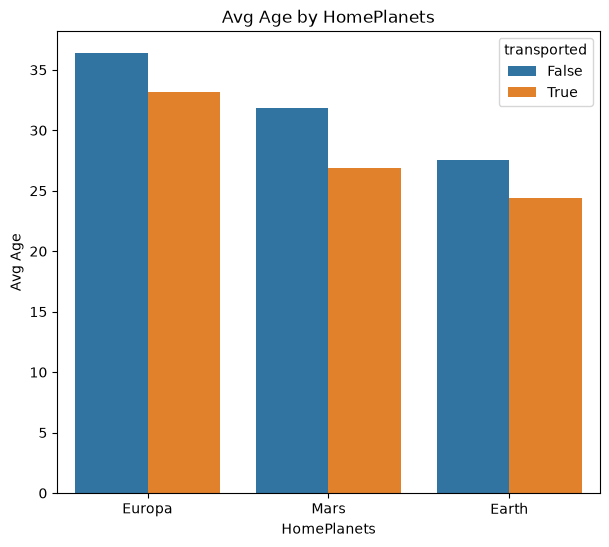

In [19]:
# Avg of age by homePlanet and target on Transport
avg_age_by_homeplanet = df.groupby(['homeplanet', 'transported'])['age'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(7, 6))

sns.barplot(data=avg_age_by_homeplanet, x='homeplanet', y='age', hue='transported')
plt.xlabel('HomePlanets')
plt.ylabel('Avg Age')
plt.title("Avg Age by HomePlanets")
plt.show()

For the oldest passengers across all planets, non-transported passengers outnumber transported passengers.

### Correlation analysis

We use heatmaps to show relationships between numerical variables.
Interpreting correlation

- -1 to -0.5 > Strong negative correlation
- -0.5 to 0 > Weak negative correlation
- 0 to 0.5 > weak positive correlation
- 0.5 to 1 > strong positive

In [20]:
# Select numerical columns
numerical_columns = df.select_dtypes(include=["int", "float"]).columns.to_list()

numerical_columns

['age', 'roomservice', 'foodcourt', 'shoppingmall', 'spa', 'vrdeck']

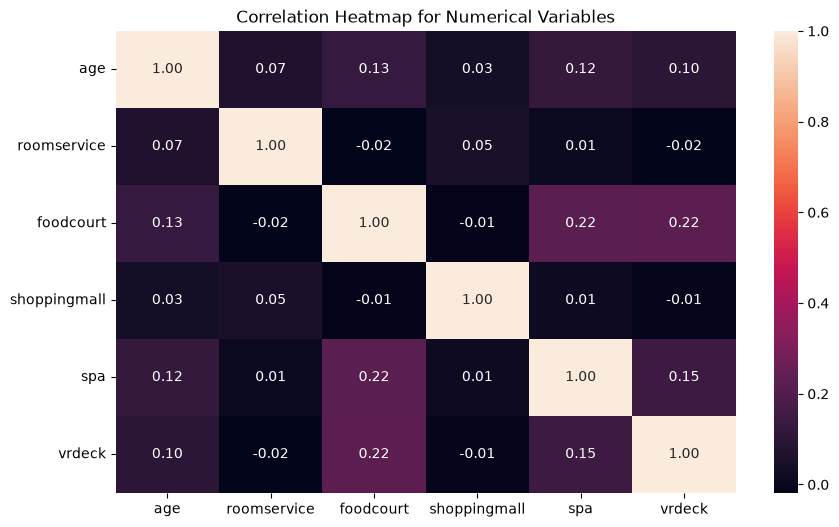

In [21]:
# Correlation analysis
correlation  = df[numerical_columns].corr()

plt.figure(figsize=(10, 6))

sns.heatmap(correlation, annot=True, fmt=".2f")
plt.title("Correlation Heatmap for Numerical Variables")
plt.show()

### Outlier Detection using the IQR Method

Outliers are extreme values that fall far outside the typical range of a feature. We detect them using the **Interquartile Range (IQR)** method:

- **Q1** = 25th percentile, **Q3** = 75th percentile
- **IQR** = Q3 − Q1
- A value is an **outlier** if it is below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR**

Below we (1) identify the numerical columns, (2) count the outliers per column, and (3) visualize them with **box plots** and a **scatter plot**.

In [22]:
numeric_cols = df.select_dtypes(include=["int", "float"]).columns.tolist()
print("Numerical columns:", numeric_cols)

outlier_summary = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)          
    Q3 = df[col].quantile(0.75)          
    IQR = Q3 - Q1                        

    lower_bound = Q1 - 1.5 * IQR        
    upper_bound = Q3 + 1.5 * IQR        

   
    is_outlier = (df[col] < lower_bound) | (df[col] > upper_bound)
    n_outliers = is_outlier.sum()

    outlier_summary.append({
        "column": col,
        "lower_bound": round(lower_bound, 2),
        "upper_bound": round(upper_bound, 2),
        "num_outliers": int(n_outliers),
        "pct_outliers": round(n_outliers / len(df) * 100, 2),
    })


outlier_summary = pd.DataFrame(outlier_summary).sort_values("num_outliers", ascending=False)
outlier_summary

Numerical columns: ['age', 'roomservice', 'foodcourt', 'shoppingmall', 'spa', 'vrdeck']


,column,lower_bound,upper_bound,num_outliers,pct_outliers
2,foodcourt,-91.5,152.5,1916,22.04
1,roomservice,-61.5,102.5,1906,21.93
3,shoppingmall,-33.0,55.0,1879,21.62
5,vrdeck,-60.0,100.0,1849,21.27
4,spa,-79.5,132.5,1833,21.09
0,age,-5.5,62.5,162,1.86


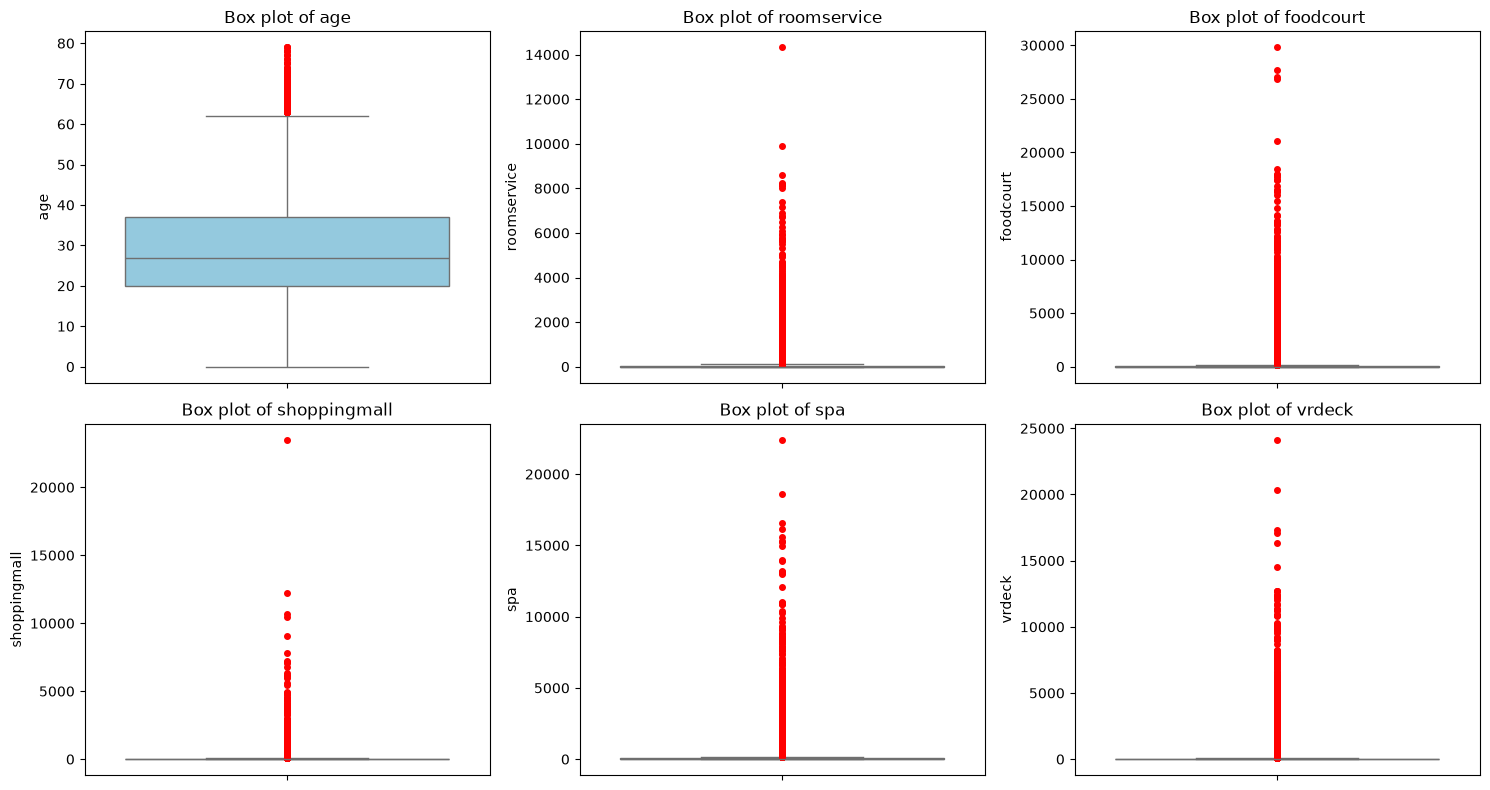

In [23]:
n_cols = 3
n_rows = -(-len(numeric_cols) // n_cols)   

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue",
                flierprops={"marker": "o", "markerfacecolor": "red",
                            "markeredgecolor": "red", "markersize": 4})
    axes[i].set_title(f"Box plot of {col}")
    axes[i].set_ylabel(col)

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

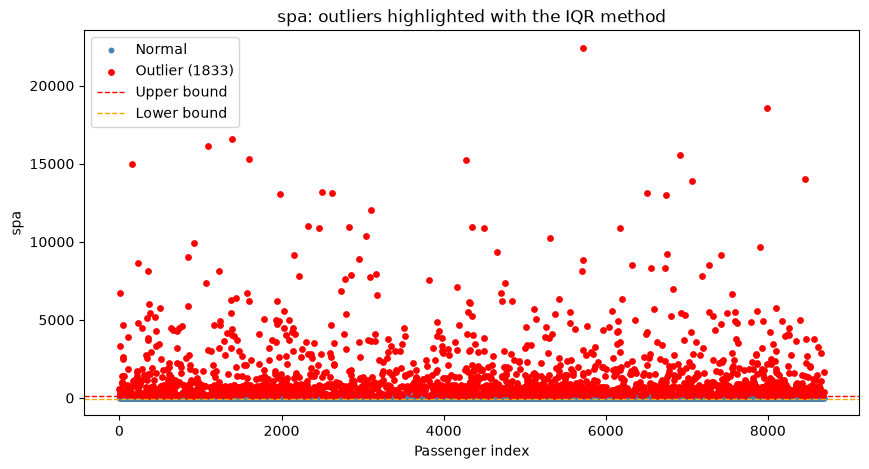

In [24]:
col = "spa"   

Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
IQR = Q3 - Q1
lower_bound, upper_bound = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR


is_outlier = (df[col] < lower_bound) | (df[col] > upper_bound)

plt.figure(figsize=(10, 5))

plt.scatter(df.index[~is_outlier], df[col][~is_outlier],
            color="steelblue", s=10, label="Normal")
plt.scatter(df.index[is_outlier], df[col][is_outlier],
            color="red", s=15, label=f"Outlier ({is_outlier.sum()})")


plt.axhline(upper_bound, color="red", linestyle="--", linewidth=1, label="Upper bound")
plt.axhline(lower_bound, color="orange", linestyle="--", linewidth=1, label="Lower bound")

plt.title(f"{col}: outliers highlighted with the IQR method")
plt.xlabel("Passenger index")
plt.ylabel(col)
plt.legend()
plt.show()